In [8]:
import os
import re
import time
import hashlib
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import kagglehub

# Verify GPU availability
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    torch.backends.cudnn.benchmark = True

Using compute device: cuda:0
GPU Model: Tesla T4


In [9]:
class ConvBNReLU(nn.Module):
    """Standard Conv2d + BatchNorm2d + ReLU."""
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size,
                      stride=stride, padding=padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DepthwiseSeparableConv(nn.Module):
    """
    Depthwise Separable Convolution:
    Depthwise Conv (spatial filtering) + Pointwise Conv 1x1 (channel mixing) + BN + ReLU.
    """
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=None):
        super().__init__()
        if padding is None:
            padding = kernel_size // 2

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=kernel_size,
                      stride=stride, padding=padding, groups=in_channels, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ModifiedInceptionA(nn.Module):
    """
    Modified Inception-A block (Figure 3b & Table 3 of the paper):
      - Branch 1: 1x1 Conv (64)
      - Branch 2: 1x1 Conv (48) -> 3x3 DS Conv (32)
      - Branch 3: 1x1 Conv (48) -> 3x3 DS Conv (32) -> 3x3 DS Conv (32)
      - Branch 4: 3x3 AvgPool (stride 1, pad 1) -> 1x1 Conv (32)
      Concatenated output = 64 + 32 + 32 + 32 = 160 channels.
      Residual shortcut: F(x) + x
    """
    def __init__(self, in_channels=160, out_channels=160):
        super().__init__()
        self.branch1 = ConvBNReLU(in_channels, 64, kernel_size=1)

        self.branch2 = nn.Sequential(
            ConvBNReLU(in_channels, 48, kernel_size=1),
            DepthwiseSeparableConv(48, 32, kernel_size=3, stride=1),
        )

        self.branch3 = nn.Sequential(
            ConvBNReLU(in_channels, 48, kernel_size=1),
            DepthwiseSeparableConv(48, 32, kernel_size=3, stride=1),
            DepthwiseSeparableConv(32, 32, kernel_size=3, stride=1),
        )

        self.branch4 = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            ConvBNReLU(in_channels, 32, kernel_size=1),
        )

        self.shortcut = (
            nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
            if in_channels != out_channels
            else nn.Identity()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        b4 = self.branch4(x)
        out = torch.cat([b1, b2, b3, b4], dim=1)
        return self.relu(out + self.shortcut(x))


class ModifiedReductionA(nn.Module):
    """
    Modified Reduction-A block (Stride 2 downsampling):
      - Branch 1: 3x3 MaxPool (stride 2, pad 1)
      - Branch 2: 1x1 Conv (48) -> 3x3 DS Conv (96, stride 2)
      - Branch 3: 1x1 Conv (48) -> 3x3 DS Conv (64) -> 3x3 DS Conv (64, stride 2)
      Output channels = 160 + 96 + 64 = 320.
    """
    def __init__(self, in_channels=160):
        super().__init__()
        self.branch1 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.branch2 = nn.Sequential(
            ConvBNReLU(in_channels, 48, kernel_size=1),
            DepthwiseSeparableConv(48, 96, kernel_size=3, stride=2, padding=1),
        )

        self.branch3 = nn.Sequential(
            ConvBNReLU(in_channels, 48, kernel_size=1),
            DepthwiseSeparableConv(48, 64, kernel_size=3, stride=1, padding=1),
            DepthwiseSeparableConv(64, 64, kernel_size=3, stride=2, padding=1),
        )

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)


class ModifiedInceptionB(nn.Module):
    """
    Modified Inception-B block (Figure 4b):
      - Branch 1: 1x1 Conv (128)
      - Branch 2: 1x1 Conv (64) -> 7x7 DS Conv (64)
      - Branch 3: 1x1 Conv (64) -> 7x7 DS Conv (64) -> 7x7 DS Conv (64)
      - Branch 4: 3x3 AvgPool (stride 1, pad 1) -> 1x1 Conv (64)
      Concatenated output = 128 + 64 + 64 + 64 = 320 channels.
      Residual shortcut: F(x) + x
    """
    def __init__(self, in_channels=320, out_channels=320):
        super().__init__()
        self.branch1 = ConvBNReLU(in_channels, 128, kernel_size=1)

        self.branch2 = nn.Sequential(
            ConvBNReLU(in_channels, 64, kernel_size=1),
            DepthwiseSeparableConv(64, 64, kernel_size=7, stride=1, padding=3),
        )

        self.branch3 = nn.Sequential(
            ConvBNReLU(in_channels, 64, kernel_size=1),
            DepthwiseSeparableConv(64, 64, kernel_size=7, stride=1, padding=3),
            DepthwiseSeparableConv(64, 64, kernel_size=7, stride=1, padding=3),
        )

        self.branch4 = nn.Sequential(
            nn.AvgPool2d(kernel_size=3, stride=1, padding=1),
            ConvBNReLU(in_channels, 64, kernel_size=1),
        )

        self.shortcut = (
            nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels),
            )
            if in_channels != out_channels
            else nn.Identity()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        b4 = self.branch4(x)
        out = torch.cat([b1, b2, b3, b4], dim=1)
        return self.relu(out + self.shortcut(x))


class ModifiedReductionB(nn.Module):
    """
    Modified Reduction-B block (Stride 2 downsampling):
      - Branch 1: 3x3 MaxPool (stride 2, pad 1)
      - Branch 2: 1x1 Conv (64) -> 3x3 DS Conv (128, stride 2)
      - Branch 3: 1x1 Conv (64) -> 3x3 DS Conv (64) -> 3x3 DS Conv (64, stride 2)
      Output channels = 320 + 128 + 64 = 512.
    """
    def __init__(self, in_channels=320):
        super().__init__()
        self.branch1 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.branch2 = nn.Sequential(
            ConvBNReLU(in_channels, 64, kernel_size=1),
            DepthwiseSeparableConv(64, 128, kernel_size=3, stride=2, padding=1),
        )

        self.branch3 = nn.Sequential(
            ConvBNReLU(in_channels, 64, kernel_size=1),
            DepthwiseSeparableConv(64, 64, kernel_size=3, stride=1, padding=1),
            DepthwiseSeparableConv(64, 64, kernel_size=3, stride=2, padding=1),
        )

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)


class NovelPlantDiseaseCNN(nn.Module):
    """
    Full Architecture (Figure 5):
      Stem -> 3x Inception-A (res) -> Reduction-A -> 3x Inception-B (res) -> Reduction-B -> GAP -> Dropout -> FC
    """
    def __init__(self, num_classes: int = 6, in_channels: int = 3, dropout_rate: float = 0.3):
        super().__init__()

        self.stem = nn.Sequential(
            ConvBNReLU(in_channels, 32, kernel_size=3, stride=1, padding=1),
            DepthwiseSeparableConv(32, 32, kernel_size=3, stride=1, padding=1),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            DepthwiseSeparableConv(32, 64, kernel_size=3, stride=1, padding=1),
            DepthwiseSeparableConv(64, 160, kernel_size=3, stride=1, padding=1),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        self.incept_a1 = ModifiedInceptionA(160, 160)
        self.incept_a2 = ModifiedInceptionA(160, 160)
        self.incept_a3 = ModifiedInceptionA(160, 160)

        self.reduction_a = ModifiedReductionA(160)

        self.incept_b1 = ModifiedInceptionB(320, 320)
        self.incept_b2 = ModifiedInceptionB(320, 320)
        self.incept_b3 = ModifiedInceptionB(320, 320)

        self.reduction_b = ModifiedReductionB(320)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.incept_a1(x)
        x = self.incept_a2(x)
        x = self.incept_a3(x)
        x = self.reduction_a(x)
        x = self.incept_b1(x)
        x = self.incept_b2(x)
        x = self.incept_b3(x)
        x = self.reduction_b(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.classifier(x)

In [11]:
# The 6 Target Tomato Classes from your list:
CANONICAL_TOMATO_CLASSES = [
    "Tomato Early Blight",
    "Tomato Late Blight",
    "Tomato Septoria Spot",
    "Tomato Leaf Mold",
    "Tomato Yellow Leaf Curl Virus",
    "Tomato Healthy",
]


def match_canonical_tomato_class(folder_name: str, full_dir_path: str, require_tomato_in_path: bool = False):
    """
    Maps dataset folder names to the 6 target classes.
    Filters out non-tomato crops (Potato/Pepper) and unrequested Tomato diseases.
    """
    norm_name = re.sub(r"[_\-\.]+", " ", folder_name.lower()).strip()
    norm_path = re.sub(r"[_\-\.]+", " ", full_dir_path.lower()).strip()

    # Exclude non-tomato crops from PlantVillage
    for other_crop in ["potato", "pepper", "bell", "corn", "maize", "apple", "grape", "peach", "cherry"]:
        if other_crop in norm_name:
            return None

    if require_tomato_in_path and "tomato" not in norm_path:
        return None

    # Strictly match to the 6 target classes
    if "early" in norm_name and "blight" in norm_name:
        return "Tomato Early Blight"
    if "late" in norm_name and "blight" in norm_name:
        return "Tomato Late Blight"
    if "septoria" in norm_name:
        return "Tomato Septoria Spot"
    if ("leaf" in norm_name and ("mold" in norm_name or "mould" in norm_name)) or norm_name in {"mold", "mould"}:
        return "Tomato Leaf Mold"
    if ("yellow" in norm_name and "curl" in norm_name) or "ylcv" in norm_name or "tylc" in norm_name or "curl virus" in norm_name:
        return "Tomato Yellow Leaf Curl Virus"
    if "healthy" in norm_name:
        return "Tomato Healthy"

    return None


def scan_dataset_for_tomato_classes(base_path: str, dataset_label: str, require_tomato_in_path: bool):
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    class_to_files = defaultdict(list)
    matched_folders = defaultdict(set)
    skipped_folders = set()

    for root, _, files in os.walk(base_path):
        img_files = [f for f in files if os.path.splitext(f)[1].lower() in valid_exts]
        if not img_files:
            continue

        folder_name = os.path.basename(root)
        canonical_cls = match_canonical_tomato_class(
            folder_name=folder_name,
            full_dir_path=root,
            require_tomato_in_path=require_tomato_in_path,
        )

        if canonical_cls is not None:
            matched_folders[canonical_cls].add(folder_name)
            for fname in img_files:
                class_to_files[canonical_cls].append(os.path.join(root, fname))
        else:
            skipped_folders.add(folder_name)

    print(f"\n--- Folder Mapping Summary for {dataset_label} ---", flush=True)
    for cls_name in CANONICAL_TOMATO_CLASSES:
        folders = sorted(matched_folders[cls_name])
        count = len(class_to_files[cls_name])
        print(f"  {cls_name:<32} <- {folders} ({count} images)", flush=True)
    if skipped_folders:
        print(f"  [Filtered out non-target folders]: {sorted(skipped_folders)}", flush=True)

    return class_to_files


class RobustImageDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


def build_combined_tomato_dataloaders(
    batch_size: int = 32,
    num_workers: int = 2,
    combined_symlink_dir: str = "./combined_tomato_6classes",
):
    # 1. Download Dataset 1: PlantVillage Dataset
    path_pv = kagglehub.dataset_download("adilmubashirchaudhry/plant-village-dataset")
    print("Path to PlantVillage dataset files:", path_pv, flush=True)

    # 2. Download Dataset 2: Tomato Leaf Disease Dataset (6 Classes)
    path_t6 = kagglehub.dataset_download("syedhashirali260/tomato-leaf-disease-dataset-6-classes")
    print("Path to Tomato 6-Classes dataset files:", path_t6, flush=True)

    # 3. Scan & Match
    pv_files = scan_dataset_for_tomato_classes(
        base_path=path_pv,
        dataset_label="Dataset 1 (PlantVillage)",
        require_tomato_in_path=True,
    )
    t6_files = scan_dataset_for_tomato_classes(
        base_path=path_t6,
        dataset_label="Dataset 2 (Tomato 6-Classes)",
        require_tomato_in_path=False,
    )

    # 4. Combine Class-wise & Symlink into unified folders
    os.makedirs(combined_symlink_dir, exist_ok=True)
    all_samples = []
    summary_rows = []

    for cls_idx, cls_name in enumerate(CANONICAL_TOMATO_CLASSES):
        safe_folder = cls_name.replace(" ", "_")
        target_cls_dir = os.path.join(combined_symlink_dir, safe_folder)
        os.makedirs(target_cls_dir, exist_ok=True)

        list_d1 = pv_files[cls_name]
        list_d2 = t6_files[cls_name]
        combined_list = list_d1 + list_d2

        for img_idx, src_path in enumerate(combined_list):
            ext = os.path.splitext(src_path)[1].lower()
            dst_link = os.path.join(target_cls_dir, f"img_{img_idx:06d}{ext}")
            if not os.path.exists(dst_link):
                try:
                    os.symlink(os.path.abspath(src_path), dst_link)
                except OSError:
                    pass
            all_samples.append((src_path, cls_idx))

        summary_rows.append(
            {
                "Class ID": cls_idx,
                "Canonical Class Name": cls_name,
                "Dataset 1 (PlantVillage)": len(list_d1),
                "Dataset 2 (Tomato-6)": len(list_d2),
                "Combined Total": len(combined_list),
            }
        )

    summary_df = pd.DataFrame(summary_rows)
    print("\n" + "=" * 85, flush=True)
    print(" CLASS-WISE COMBINED DATASET SUMMARY (6 TARGET TOMATO CLASSES)", flush=True)
    print("=" * 85, flush=True)
    print(summary_df.to_string(index=False), flush=True)
    print("-" * 85, flush=True)
    print(f" Total Combined Images Across All 6 Classes: {len(all_samples):,}", flush=True)
    print(f" Unified Class-wise Directory Created At   : {os.path.abspath(combined_symlink_dir)}", flush=True)
    print("=" * 85, flush=True)

    # 5. Stratified 80:20 Train / Validation Split (Paper Section IV.A)
    labels = [s[1] for s in all_samples]
    train_samples, val_samples = train_test_split(
        all_samples, test_size=0.20, random_state=42, stratify=labels
    )

    train_transform = transforms.Compose(
        [
            transforms.Resize((256, 256)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.2),
            transforms.RandomRotation(degrees=15),
            transforms.ColorJitter(brightness=0.1, contrast=0.1),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ]
    )

    val_transform = transforms.Compose(
        [
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ]
    )

    train_ds = RobustImageDataset(train_samples, transform=train_transform)
    val_ds = RobustImageDataset(val_samples, transform=val_transform)

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=True
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=True
    )

    print(f"[+] Stratified Split -> Train: {len(train_ds):,} images | Validation: {len(val_ds):,} images\n", flush=True)
    return train_loader, val_loader, CANONICAL_TOMATO_CLASSES

In [12]:
def convert_and_verify_tflite(checkpoint_path: str, crop_name: str, class_names: list, val_loader: DataLoader):
    """Exports best PyTorch checkpoint to ONNX and TFLite (FP32 & FP16 quantized)."""
    import tensorflow as tf
    import onnx2tf

    print("\n" + "=" * 70, flush=True)
    print(f" EXPORTING {crop_name.upper()} MODEL TO TFLITE (.tflite)", flush=True)
    print("=" * 70, flush=True)

    ckpt = torch.load(checkpoint_path, map_location="cpu")
    model_cpu = NovelPlantDiseaseCNN(num_classes=len(class_names), dropout_rate=0.0)
    model_cpu.load_state_dict(ckpt["model_state_dict"])
    model_cpu.eval()

    onnx_path = f"novel_cnn_{crop_name.lower()}.onnx"
    tf_saved_model_dir = f"saved_model_{crop_name.lower()}"
    tflite_fp32_path = f"novel_cnn_{crop_name.lower()}_fp32.tflite"
    tflite_fp16_path = f"novel_cnn_{crop_name.lower()}_fp16.tflite"

    # 1. PyTorch -> ONNX
    dummy_input = torch.randn(1, 3, 256, 256, dtype=torch.float32)
    torch.onnx.export(
        model_cpu, dummy_input, onnx_path, export_params=True, opset_version=13,
        do_constant_folding=True, input_names=["input_rgb"], output_names=["disease_logits"],
    )
    print(f"[1/3] Exported ONNX model: {onnx_path} ({os.path.getsize(onnx_path)/1e6:.2f} MB)", flush=True)

    # 2. ONNX -> TF SavedModel -> TFLite
    onnx2tf.convert(
        input_onnx_file_path=onnx_path,
        output_folder_path=tf_saved_model_dir,
        copy_onnx_input_output_names_to_tflite=True,
        non_verbose=True,
    )

    # FP32 TFLite
    conv_fp32 = tf.lite.TFLiteConverter.from_saved_model(tf_saved_model_dir)
    with open(tflite_fp32_path, "wb") as f:
        f.write(conv_fp32.convert())

    # FP16 Quantized TFLite
    conv_fp16 = tf.lite.TFLiteConverter.from_saved_model(tf_saved_model_dir)
    conv_fp16.optimizations = [tf.lite.Optimize.DEFAULT]
    conv_fp16.target_spec.supported_types = [tf.float16]
    with open(tflite_fp16_path, "wb") as f:
        f.write(conv_fp16.convert())

    print(f"[2/3] Created FP32 TFLite: {tflite_fp32_path} ({os.path.getsize(tflite_fp32_path)/1e6:.2f} MB)", flush=True)
    print(f"      Created FP16 TFLite: {tflite_fp16_path} ({os.path.getsize(tflite_fp16_path)/1e6:.2f} MB)", flush=True)

    # 3. Verification
    interpreter = tf.lite.Interpreter(model_path=tflite_fp32_path)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    sample_imgs, sample_labels = next(iter(val_loader))
    sample_img_nchw = sample_imgs[0:1].numpy()
    expected_shape = tuple(input_details[0]["shape"])

    if expected_shape == (1, 256, 256, 3):
        tflite_input = np.transpose(sample_img_nchw, (0, 2, 3, 1)).astype(np.float32)
    else:
        tflite_input = sample_img_nchw.astype(np.float32)

    interpreter.set_tensor(input_details[0]["index"], tflite_input)
    interpreter.invoke()
    tflite_logits = interpreter.get_tensor(output_details[0]["index"])[0]
    pred_cls = class_names[int(np.argmax(tflite_logits))]
    true_cls = class_names[int(sample_labels[0].item())]

    print(f"[3/3] Verification Passed! Shape: {expected_shape} | Predicted: '{pred_cls}' | True: '{true_cls}'", flush=True)
    return tflite_fp32_path, tflite_fp16_path

Path to PlantVillage dataset files: /kaggle/input/datasets/adilmubashirchaudhry/plant-village-dataset
Path to Tomato 6-Classes dataset files: /kaggle/input/datasets/syedhashirali260/tomato-leaf-disease-dataset-6-classes

--- Folder Mapping Summary for Dataset 1 (PlantVillage) ---
  Tomato Early Blight              <- ['Tomato_Early_blight'] (3000 images)
  Tomato Late Blight               <- ['Tomato_Late_blight'] (5727 images)
  Tomato Septoria Spot             <- ['Tomato_Septoria_leaf_spot'] (5313 images)
  Tomato Leaf Mold                 <- ['Tomato_Leaf_Mold'] (2856 images)
  Tomato Yellow Leaf Curl Virus    <- ['Tomato__Tomato_YellowLeaf__Curl_Virus'] (9624 images)
  Tomato Healthy                   <- ['Tomato_healthy'] (4773 images)
  [Filtered out non-target folders]: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__T

Epoch 01/50 [Train]:   0%|          | 0/933 [00:00<?, ?it/s]

01/50    |       0.6615 |      77.52% |     0.3180 |     88.63% |     86.03% |   0.001000 | 2074.3s *


Epoch 02/50 [Train]:   0%|          | 0/933 [00:00<?, ?it/s]

02/50    |       0.3178 |      89.28% |     0.2135 |     93.03% |     92.02% |   0.000999 |  271.7s *


...

Epoch 49/50 [Train]:   0%|          | 0/933 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f833eb0c220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x7f833eb0c220>

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
self._shutdown_workers()AssertionError
: can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():
  File "/usr/lib/

49/50    |       0.0059 |      99.79% |     0.0087 |     99.79% |     99.76% |   0.000004 |  267.1s


Epoch 50/50 [Train]:   0%|          | 0/933 [00:00<?, ?it/s]

50/50    |       0.0055 |      99.80% |     0.0082 |     99.76% |     99.73% |   0.000001 |  266.8s
[+] Tomato Training Complete! Best Validation Accuracy: 99.81%

--- Final Combined Tomato (6 Classes) Test Classification Report ---
                               precision    recall  f1-score   support

          Tomato Early Blight     0.9976    0.9905    0.9940       840
           Tomato Late Blight     0.9971    0.9986    0.9978      1385
         Tomato Septoria Spot     1.0000    1.0000    1.0000      1063
             Tomato Leaf Mold     0.9963    1.0000    0.9982       811
Tomato Yellow Leaf Curl Virus     0.9977    0.9995    0.9986      2165
               Tomato Healthy     1.0000    0.9975    0.9987      1195

                     accuracy                         0.9981      7459
                    macro avg     0.9981    0.9977    0.9979      7459
                 weighted avg     0.9981    0.9981    0.9981      7459



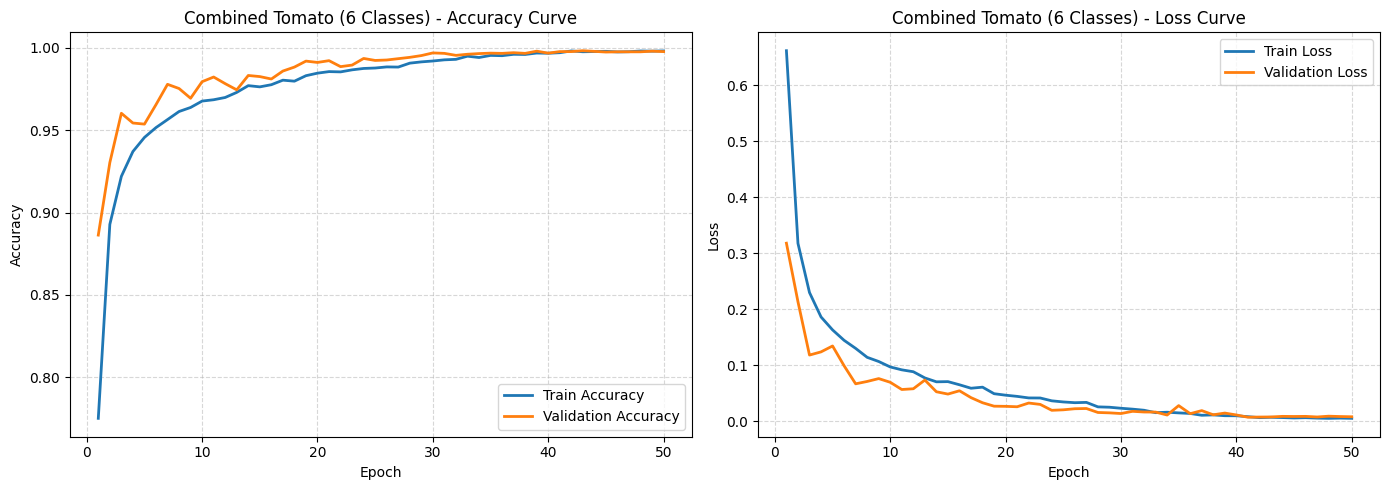

NameError: name 'sns' is not defined

<Figure size 800x650 with 0 Axes>

In [13]:
EPOCHS_TOMATO = 50
BATCH_SIZE_TOMATO = 32
LR_TOMATO = 1e-3

# 1. Prepare Combined DataLoaders
tm_train_loader, tm_val_loader, tm_classes = build_combined_tomato_dataloaders(
    batch_size=BATCH_SIZE_TOMATO, num_workers=2
)

# 2. Instantiate Model
tm_model = NovelPlantDiseaseCNN(num_classes=len(tm_classes), dropout_rate=0.3).to(device)
tm_params = sum(p.numel() for p in tm_model.parameters() if p.requires_grad)
print(f"[+] Model Initialized | Classes: {len(tm_classes)} | Trainable Parameters: {tm_params:,}\n", flush=True)

tm_criterion = nn.CrossEntropyLoss()
tm_optimizer = torch.optim.Adam(tm_model.parameters(), lr=LR_TOMATO, weight_decay=1e-4)
tm_scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
tm_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(tm_optimizer, T_max=EPOCHS_TOMATO)

tm_history = []
tm_best_val_acc = 0.0
tm_ckpt_path = "novel_cnn_tomato_6classes_best.pth"

print("=" * 95, flush=True)
print(f"{'Epoch':^9} | {'Train Loss':^12} | {'Train Acc':^11} | {'Val Loss':^10} | {'Val Acc':^10} | {'Val F1':^10} | {'LR':^10} | {'Time':^8}", flush=True)
print("=" * 95, flush=True)

# 3. Explicit Per-Epoch Training Loop
for epoch in range(1, EPOCHS_TOMATO + 1):
    t_start = time.time()

    # --- Training ---
    tm_model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0
    train_pbar = tqdm(tm_train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS_TOMATO:02d} [Train]", leave=False)

    for images, labels in train_pbar:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        tm_optimizer.zero_grad()
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            outputs = tm_model(images)
            loss = tm_criterion(outputs, labels)

        tm_scaler.scale(loss).backward()
        tm_scaler.step(tm_optimizer)
        tm_scaler.update()

        train_loss_sum += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        train_correct += preds.eq(labels).sum().item()
        train_total += labels.size(0)
        train_pbar.set_postfix(loss=f"{train_loss_sum/train_total:.4f}", acc=f"{100.0*train_correct/train_total:.2f}%")

    epoch_train_loss = train_loss_sum / train_total
    epoch_train_acc = train_correct / train_total

    # --- Validation ---
    tm_model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    val_preds_epoch, val_targets_epoch = [], []

    with torch.no_grad():
        for images, labels in tm_val_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                outputs = tm_model(images)
                loss = tm_criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            val_correct += preds.eq(labels).sum().item()
            val_total += labels.size(0)
            val_preds_epoch.extend(preds.cpu().numpy())
            val_targets_epoch.extend(labels.cpu().numpy())

    epoch_val_loss = val_loss_sum / val_total
    epoch_val_acc = val_correct / val_total
    _, _, epoch_val_f1, _ = precision_recall_fscore_support(
        val_targets_epoch, val_preds_epoch, average="macro", zero_division=0
    )

    current_lr = tm_optimizer.param_groups[0]["lr"]
    tm_scheduler.step()
    elapsed = time.time() - t_start

    saved_marker = ""
    if epoch_val_acc > tm_best_val_acc:
        tm_best_val_acc = epoch_val_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": tm_model.state_dict(),
            "class_names": tm_classes,
            "best_val_acc": tm_best_val_acc,
        }, tm_ckpt_path)
        saved_marker = " *"

    tm_history.append({
        "epoch": epoch, "train_loss": epoch_train_loss, "train_acc": epoch_train_acc,
        "val_loss": epoch_val_loss, "val_acc": epoch_val_acc, "val_f1": epoch_val_f1,
        "lr": current_lr, "time_sec": elapsed,
    })

    print(
        f"{epoch:02d}/{EPOCHS_TOMATO:02d}    | "
        f"{epoch_train_loss:12.4f} | "
        f"{epoch_train_acc*100:10.2f}% | "
        f"{epoch_val_loss:10.4f} | "
        f"{epoch_val_acc*100:9.2f}% | "
        f"{epoch_val_f1*100:9.2f}% | "
        f"{current_lr:10.6f} | "
        f"{elapsed:6.1f}s{saved_marker}",
        flush=True,
    )

print("=" * 95, flush=True)
print(f"[+] Tomato Training Complete! Best Validation Accuracy: {tm_best_val_acc*100:.2f}%", flush=True)

# 4. Final Test Set Evaluation
tm_ckpt = torch.load(tm_ckpt_path, map_location=device)
tm_model.load_state_dict(tm_ckpt["model_state_dict"])
tm_model.eval()

tm_test_preds, tm_test_targets = [], []
with torch.no_grad():
    for images, labels in tm_val_loader:
        images = images.to(device)
        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            outputs = tm_model(images)
        _, preds = outputs.max(1)
        tm_test_preds.extend(preds.cpu().numpy())
        tm_test_targets.extend(labels.numpy())

print("\n--- Final Combined Tomato (6 Classes) Test Classification Report ---", flush=True)
print(classification_report(tm_test_targets, tm_test_preds, target_names=tm_classes, digits=4), flush=True)

# Plots
tm_df = pd.DataFrame(tm_history)
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(tm_df["epoch"], tm_df["train_acc"], label="Train Accuracy", lw=2)
plt.plot(tm_df["epoch"], tm_df["val_acc"], label="Validation Accuracy", lw=2)
plt.title("Combined Tomato (6 Classes) - Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(tm_df["epoch"], tm_df["train_loss"], label="Train Loss", lw=2)
plt.plot(tm_df["epoch"], tm_df["val_loss"], label="Validation Loss", lw=2)
plt.title("Combined Tomato (6 Classes) - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("tomato_6classes_curves.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 6.5))
sns.heatmap(
    confusion_matrix(tm_test_targets, tm_test_preds),
    annot=True, fmt="d", cmap="Reds", xticklabels=tm_classes, yticklabels=tm_classes,
)
plt.title("Combined Tomato (6 Classes) - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("tomato_6classes_confusion_matrix.png", dpi=300)
plt.show()

# 5. Export to TFLite
tm_tflite_fp32, tm_tflite_fp16 = convert_and_verify_tflite(
    checkpoint_path=tm_ckpt_path, crop_name="tomato_6classes",
    class_names=tm_classes, val_loader=tm_val_loader,
)